In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
# suppress warnings
import warnings
warnings.simplefilter('ignore')

### Load data and clean

In [2]:
# Read in TSD and rates data
tsd_path = '/Users/Kathy/Library/CloudStorage/OneDrive-UW/Desktop/UW/seaflow/decomposition_project/data/all_seaflow_tsd_mixed_v1_all.pickle'
rates_path = '/Users/Kathy/Library/CloudStorage/OneDrive-UW/Desktop/UW/seaflow/decomposition_project/data/final_rates_v1_all.pickle'

all_tsd = pd.read_pickle(tsd_path)
final_rates = pd.read_pickle(rates_path)
# only get good tsd dimensions
good_tsd = final_rates[['cruise', 'cruise_day', 'pop', 'model', 'daily_growth']].merge(all_tsd, how = 'left')

# subset rates data for cruises by Station ALOHA
aloha_cruises = list(final_rates.loc[final_rates['ALOHA'] > 0, 'cruise'].unique())
# add diel cruise
aloha_cruises.append('KM1513')

aloha_df = final_rates.loc[final_rates['cruise'].isin(aloha_cruises)][['cruise', 
                                                                       'cruise_day', 
                                                                       'pop', 
                                                                       'model', 
                                                                       'daily_growth',
                                                                       'productivity']]
# merge with tsd components df
all_aloha = aloha_df.merge(all_tsd, how = 'left')
# make a copy 
pop_cruise = all_aloha.copy()
# make plots of log diel 
pop_cruise['log_diel'] = np.log(pop_cruise['diel'])

Merge with SFL data

In [3]:
hourly_sfl = pd.read_csv('../data/hourly_sfl.csv')
# fix time
hourly_sfl['time'] = pd.DatetimeIndex(hourly_sfl['time']).tz_convert('UTC')
# merge with colocalized rates
cruise_sfl = hourly_sfl.loc[hourly_sfl['cruise'].isin(aloha_cruises)]
hot_cruise = pop_cruise.drop(columns = ['par']).merge(cruise_sfl, on = ['time', 'cruise'], how = 'left')
# create a column for each hour of each day 
hot_cruise['day_hour'] = hot_cruise.groupby(['pop', 'cruise', 'cruise_day']).cumcount()

Accomodate incomplete days by recalculating each day's hour starting from sunrise

In [4]:
## calculate hour per day starting from sunrise (hour 0)
pops = ['prochloro', 'synecho', 'picoeuk']
dfs = []
for cruise in hot_cruise['cruise'].unique():
    cruise_df = hot_cruise.loc[hot_cruise['cruise'] == cruise] 
    # do this for each population
    for pop in pops:
        # subset df
        df = cruise_df.loc[cruise_df['pop'] == pop].reset_index(drop=True)
        # skip if empty
        if df.empty:
            continue
        df["time"] = pd.to_datetime(df["time"])
        # recalculate day hour
        df['day_hour'] = df.groupby(['pop', 'cruise_day']).cumcount()
        # check for edge case such that day 1 starts before sunrise
        df_counts = df.groupby(['cruise_day'])['time'].count().reset_index()
        day1_len = df_counts.loc[0, 'time']
        first_cruise_day = df_counts.loc[0, 'cruise_day']
        # boolean for defining start of day
        sunrise_start = df.loc[df['cruise_day'] == first_cruise_day, 'time_of_day'][0] == 'sunrise'
        # check for partial day on first day that doesn't start at sunrise
        if (~sunrise_start) &  (day1_len < 24):
            # calculate offset
            # offset = 24 - day_len so that the first hour of that day gets this value
            offset = 24 - day1_len
            # shift day_hour for the entire first group (group_id == 0)
            df.loc[df['cruise_day'] == first_cruise_day, "day_hour"] += offset
        dfs.append(df)
    
hot_cruise_new = pd.concat(dfs).reset_index(drop = True)

#### Plot overall time series
- Qc
- Growth rate
- Productivity
- Division rate (from Francois data)

In [5]:
from datetime import datetime, timedelta

# plot diel cruise only & pro only
diel_cruise = hot_cruise_new.loc[(hot_cruise_new['cruise'] == 'KM1513') & 
                                 (hot_cruise_new['pop'] == 'prochloro')].reset_index(drop = True)
# read in raw Qc data
sf_clean = pd.read_pickle('../../../seaflow/decomposition_project/data/sf_clean_long_all.pickle')
diel_qc = sf_clean.loc[(sf_clean['cruise'] == 'KM1513') & 
             (sf_clean['pop'] == 'prochloro')].sort_values(by='time').set_index('time')
# subset
diel_qc = diel_qc.loc['2015-07-25 16:00:00+00:00':]
# resample
diel_qc = diel_qc.resample('1H').agg(pd.Series.sum, min_count=1).reset_index()
# get TSD rates data only
diel_cruise_rates = final_rates.loc[(final_rates['pop'] == 'prochloro') & 
                (final_rates['cruise'] == 'KM1513')]
# shift time by one day
diel_cruise_rates['time'] = pd.to_datetime(diel_cruise_rates['time']) + timedelta(days = 1)

# read in MPM data
mpm_df = pd.read_csv('../data/ribalet_2025_mpm.csv')
# cruise name in MPM dataset
cruise_name = 'HOE-Legacy 2A'
diel_mpm = mpm_df.loc[mpm_df['cruise'] == cruise_name]
diel_mpm['time'] = pd.DatetimeIndex(diel_mpm['time']).tz_convert('UTC')
# calculate standard error
diel_mpm['division_se'] = diel_mpm['division_sd'] / np.sqrt(diel_mpm['n'])

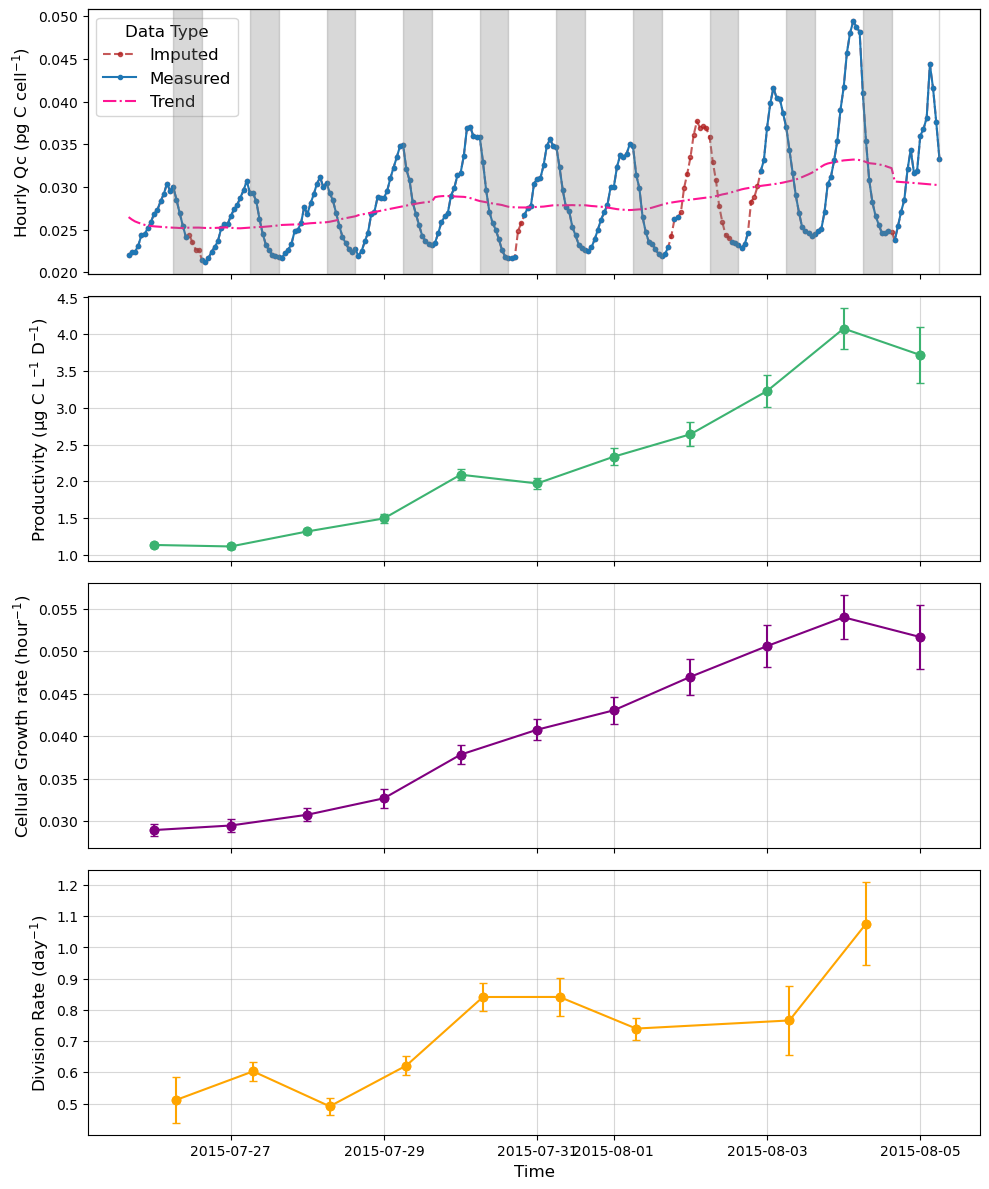

In [6]:
# create figure
nrows = 4
fig, axs = plt.subplots(figsize=(10, 12), nrows = nrows, sharex= True)
## plot time series data
# plot imputed data
axs[0].plot(diel_cruise['time'], diel_cruise['data_with_missing'], marker='.', c = 'firebrick', alpha=0.75, label='Imputed', linestyle='--')
# plot orignal data
axs[0].plot(diel_qc['time'], diel_qc['Qc_hour'], marker='.', label='Measured')
# plot trend
axs[0].plot(diel_cruise['time'], diel_cruise['trend'], linestyle='-.', c='deeppink', label='Trend')
# plot diel cycle
twinax=axs[0].twinx()
twinax.fill_between(diel_cruise['time'], 0, 1, where=diel_cruise['time_of_day'] == 'night',color='gray', alpha=0.3, 
                    transform=axs[0].get_xaxis_transform())
# set y limits
ylims = axs[0].get_ylim()
twinax.set_ylim(ylims[0],ylims[1])
# # hide y ticks
twinax.tick_params(left=False, labelleft=False, top=False, labeltop=False,
                right=False, labelright=False, bottom=False, labelbottom=False)

## plot rates data
# productivity
x = diel_cruise_rates['time']
y = diel_cruise_rates['productivity']
yerr = diel_cruise_rates['productivity_se']
# plot growth + error bars (se)
axs[1].errorbar(x, y, yerr=yerr, capsize=3, ecolor = "mediumseagreen", color = "mediumseagreen", fmt='o')
l1 = axs[1].plot(x, y, c = 'mediumseagreen', label='Productivity', marker='o')
# add grid
axs[1].grid(alpha=0.5)

# growth rates
x = diel_cruise_rates['time']
y = diel_cruise_rates['daily_growth']
yerr = diel_cruise_rates['daily_se']
# plot growth + error bars (se)
axs[2].errorbar(x, y, yerr=yerr, capsize=3, ecolor = "purple", color = "purple", fmt='o')
l1 = axs[2].plot(x, y, c = 'purple', label='Growth', marker='o')
# add grid
axs[2].grid(alpha=0.5)

# divison rates (MPM)
x = diel_mpm['time']
y = diel_mpm['division']
yerr = diel_mpm['division_se']
# plot growth + error bars (se)
axs[3].errorbar(x, y, yerr=yerr, capsize=3, ecolor = "orange", color = "orange", fmt='o')
l1 = axs[3].plot(x, y, c = 'orange', label='Division', marker='o')
# add grid
axs[3].grid(alpha=0.5)

## plot aesthetics
axs[0].legend(title='Data Type', fontsize=12, title_fontsize=12)
# axis labels
axs[0].set_ylabel('Hourly Qc (pg C $\mathregular{cell^{-1}}$)', fontsize=12)
axs[1].set_ylabel('Productivity (µg C $\mathregular{{L^{{-1}}}}$ $\mathregular{{D^{{-1}}}}$)', fontsize=12)
axs[2].set_ylabel('Cellular Growth rate ($\mathregular{{hour^{{-1}}}}$)', fontsize=12)
axs[3].set_ylabel('Division Rate ($\mathregular{{day^{{-1}}}}$)', fontsize=12)
axs[nrows - 1].set_xlabel('Time', fontsize=12)

plt.tight_layout()

#### Plot pro, syn, picoeuk Qc over time for diel cruise

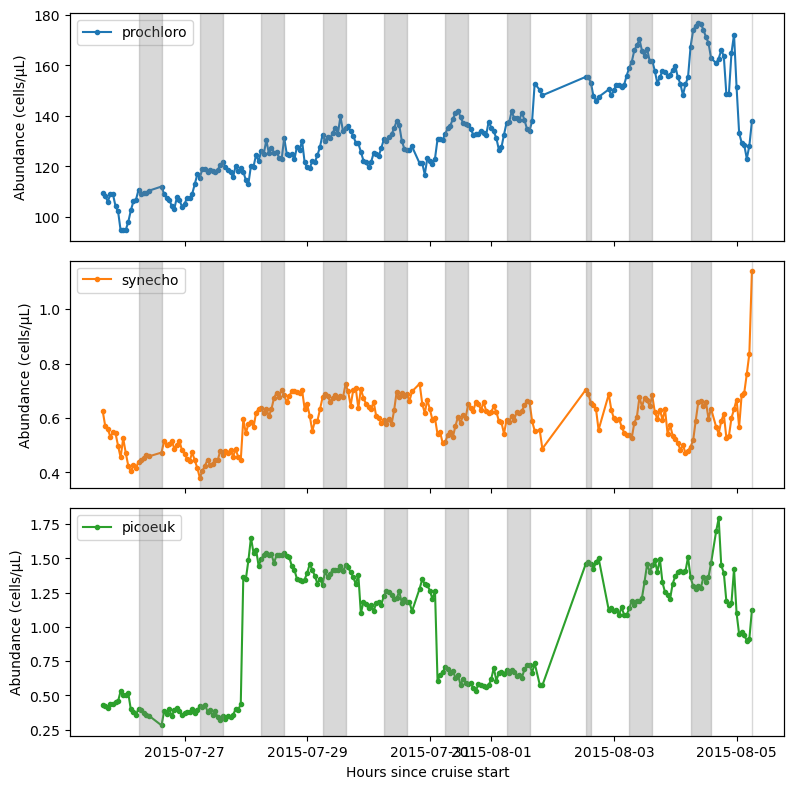

In [7]:
# loop through each cruise and print diel times
pops = ['prochloro', 'synecho', 'picoeuk']
colors = ['tab:blue', 'tab:orange', 'tab:green']
cruise = 'KM1513'

# merge with hourly data to get time of day
diel_pops = sf_clean.loc[(sf_clean['cruise'] == 'KM1513')].sort_values(by='time')
diel_df = diel_cruise[['cruise_day', 'time', 'time_of_day']].merge(diel_pops, how = 'left')
## plot
fig, axs = plt.subplots(sharex= True, nrows = 3, figsize = (8, 8))
counter = 0
# loop thru each population
for pop, c in zip(pops, colors):
    pop_df = diel_df.loc[diel_df['pop'] == pop]
    # plot diel cycle over time
    x=pop_df['time']
    y=pop_df['abundance']
    # plot
    axs[counter].plot(x, y,marker='.', c=c, label = pop)
    # show day/nightii
    twinax=axs[counter].twinx()
    twinax.fill_between(pop_df['time'], 0, 1, where=pop_df['time_of_day']=='night',color='gray',
                        alpha=0.3, transform=axs[counter].get_xaxis_transform())
    # hide y ticks
    twinax.tick_params(left=False, labelleft=False, top=False, labeltop=False,
                        right=False, labelright=False, bottom=False, labelbottom=False)

    axs[counter].set_ylabel('Abundance (cells/µL)')
    # cruise=pd.unique(diel_df['cruise'])[0]
    # axs.set_title(f'{cruise}: {pop}')
    axs[counter].legend()
    counter += 1
axs[2].set_xlabel('Hours since cruise start')
plt.tight_layout()
plt.show()